# Bài 1 — Phân tích và phân đoạn ảnh màu

Chạy từ repository hoặc thư mục `notebooks/`. Kết quả lưu tại `outputs/bai_1/`; các ngưỡng bên dưới là giá trị khảo sát ban đầu.


In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import csv

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Không tìm thấy data/; chạy notebook từ repository hoặc notebooks/")
sys.path.insert(0, str(ROOT))
from src.color_utils import rgb_to_hsi, segment_color_rgb, segment_color_hsv

paths = {
    "strawberries": "Fig0630(01)(strawberries_fullcolor).tif",
    "chalk": "Fig0635(middle_row_left_chalk ).tif",
}
images = {}
for name, filename in paths.items():
    path = ROOT / "data" / "DIP3E_Original_Images_CH06" / filename
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)
    images[name] = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    print(name, filename, images[name].shape, images[name].dtype)
OUT = ROOT / "outputs" / "bai_1"
def save(fig, folder, filename):
    directory = OUT / folder
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


strawberries Fig0630(01)(strawberries_fullcolor).tif (666, 666, 3) uint8
chalk Fig0635(middle_row_left_chalk ).tif (1040, 1040, 3) uint8


## 1. Các không gian màu

HSV và Lab hiển thị theo thang `uint8` của OpenCV; HSI dùng Hue theo độ và S, I trong [0, 1]. Hue của pixel xám được quy ước bằng 0.


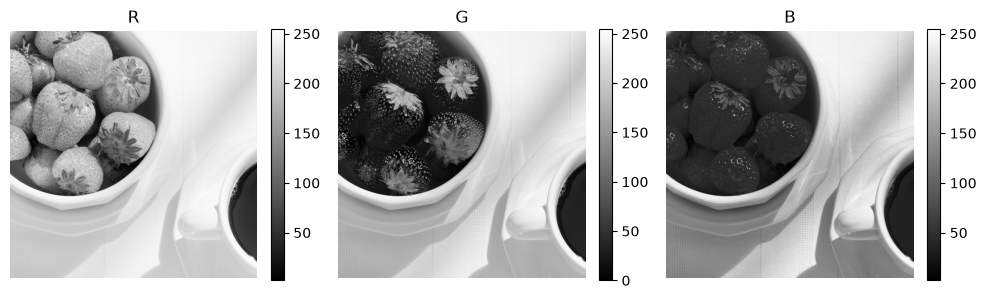

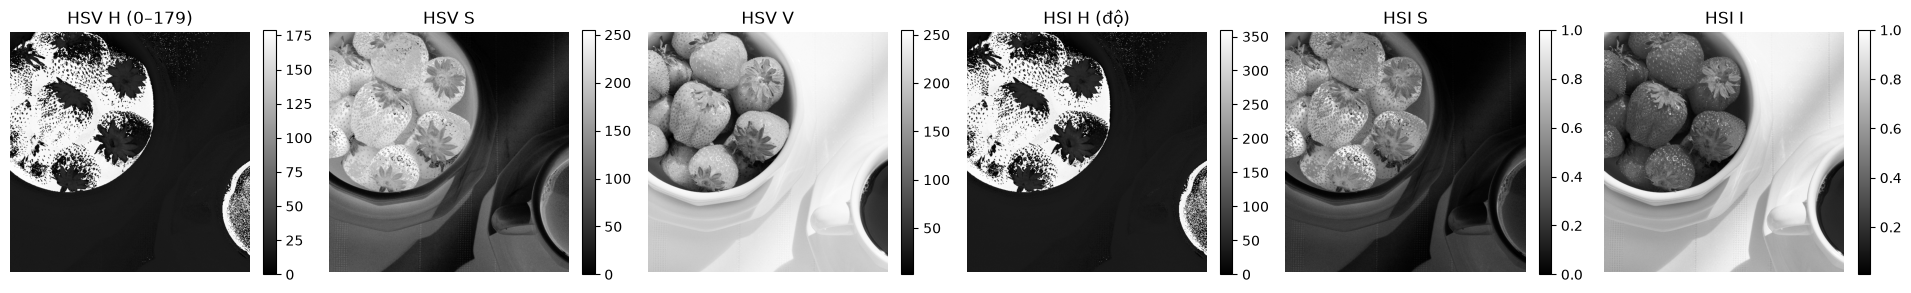

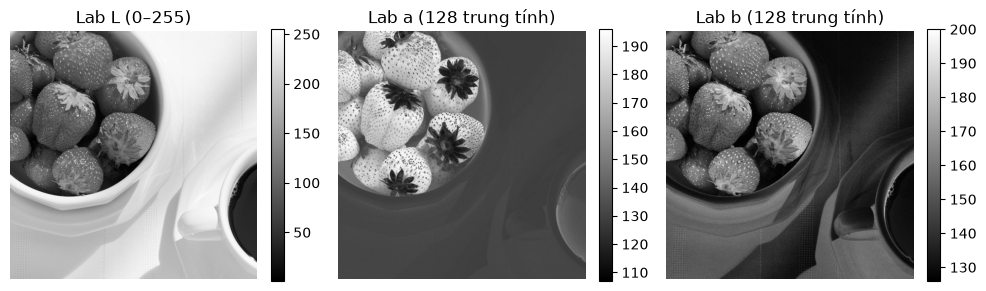

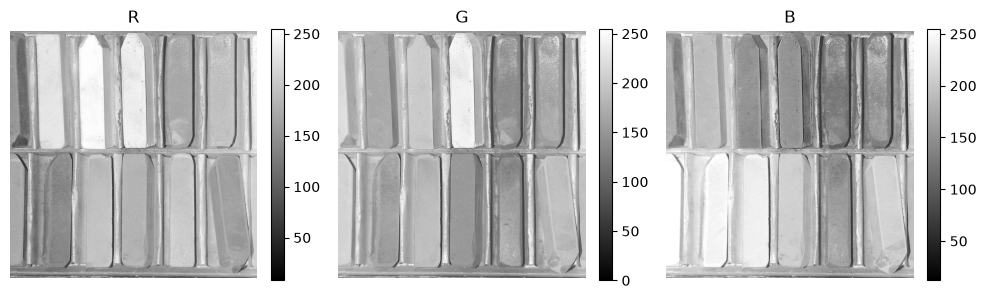

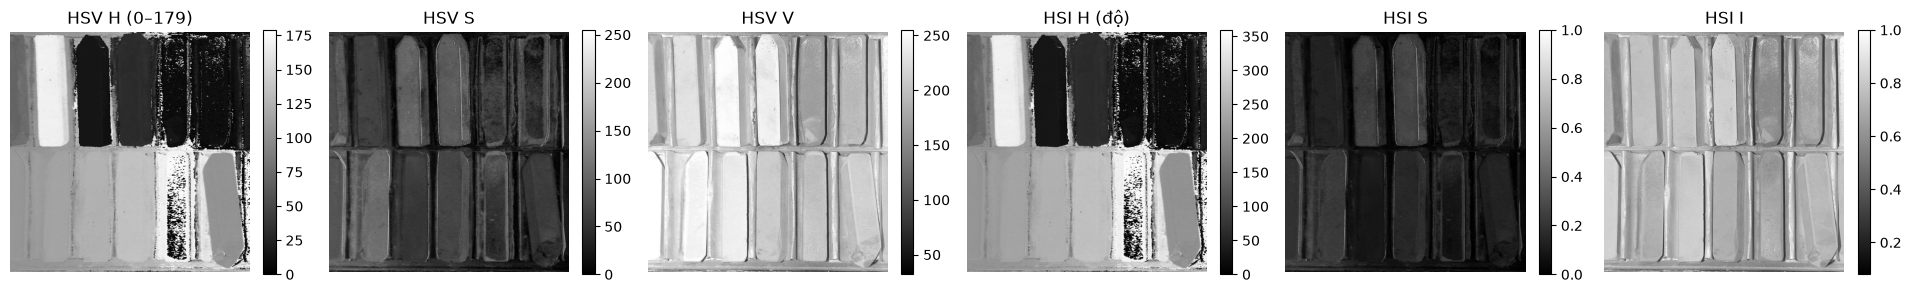

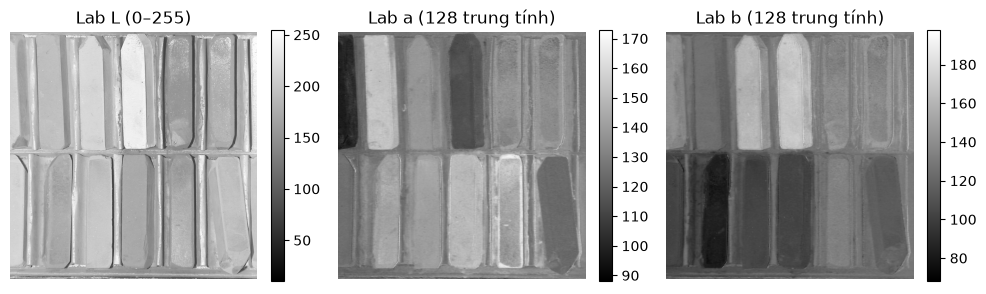

In [2]:
for name, rgb in images.items():
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    h, s, intensity = rgb_to_hsi(rgb)
    groups = [
        ("rgb", [rgb[:, :, i] for i in range(3)], ["R", "G", "B"]),
        ("hsv_hsi", [hsv[:, :, i] for i in range(3)] + [h, s, intensity],
         ["HSV H (0–179)", "HSV S", "HSV V", "HSI H (độ)", "HSI S", "HSI I"]),
        ("cielab", [lab[:, :, i] for i in range(3)], ["Lab L (0–255)", "Lab a (128 trung tính)", "Lab b (128 trung tính)"]),
    ]
    directory = OUT / "1.1_color_spaces"
    directory.mkdir(parents=True, exist_ok=True)
    plt.imsave(directory / f"1.1_{name}_input.png", rgb)
    for group, channels, titles in groups:
        fig, axes = plt.subplots(1, len(channels), figsize=(4 * len(channels), 4))
        for ax, channel, title in zip(axes, channels, titles):
            im = ax.imshow(channel, cmap="gray")
            ax.set_title(title)
            ax.axis("off")
            fig.colorbar(im, ax=ax, fraction=.046)
        save(fig, "1.1_color_spaces", f"1.1_{name}_output_{group}_channels.png")


## 2. Phân đoạn theo màu

So sánh mask RGB và HSV trên cùng ảnh. Các ngưỡng có thể bỏ sót vùng bóng hoặc chọn nhầm nền; quan sát hình trước khi kết luận.


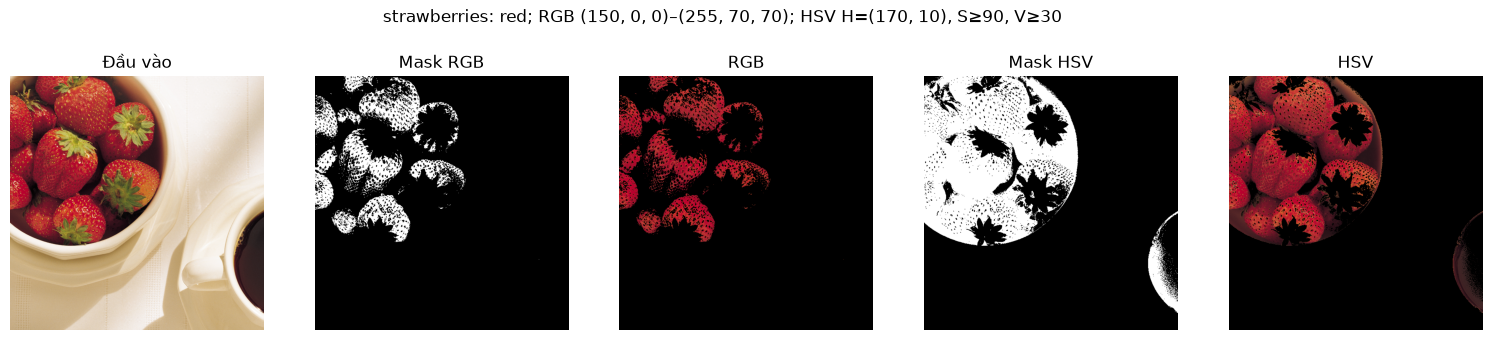

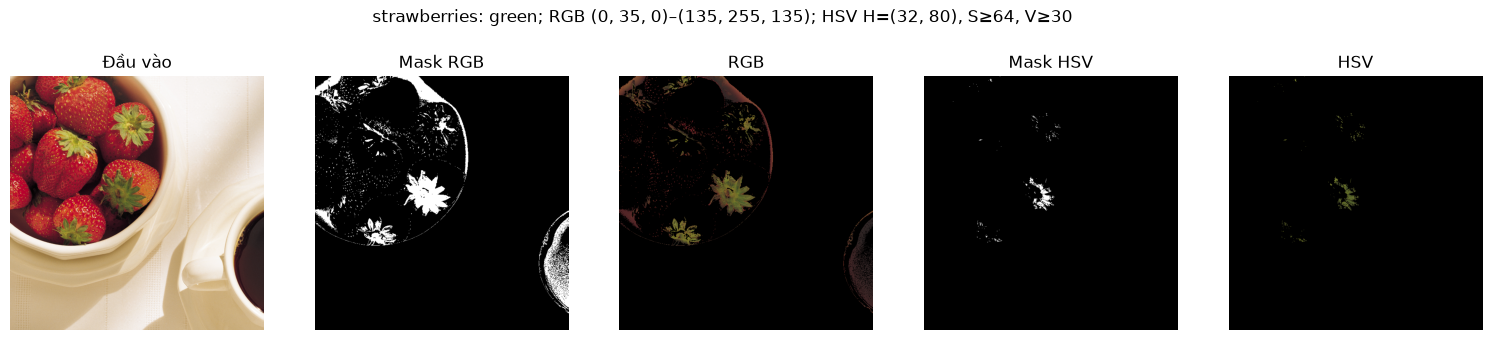

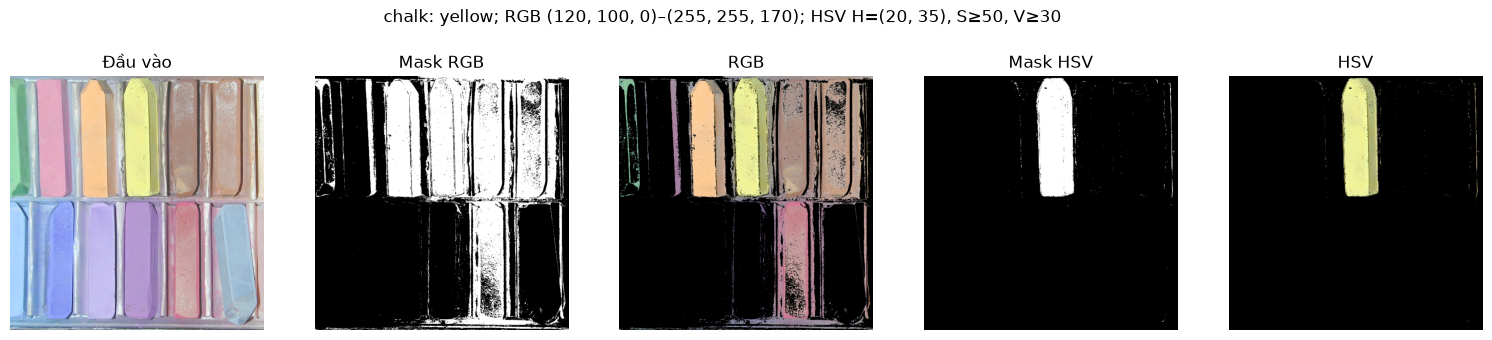

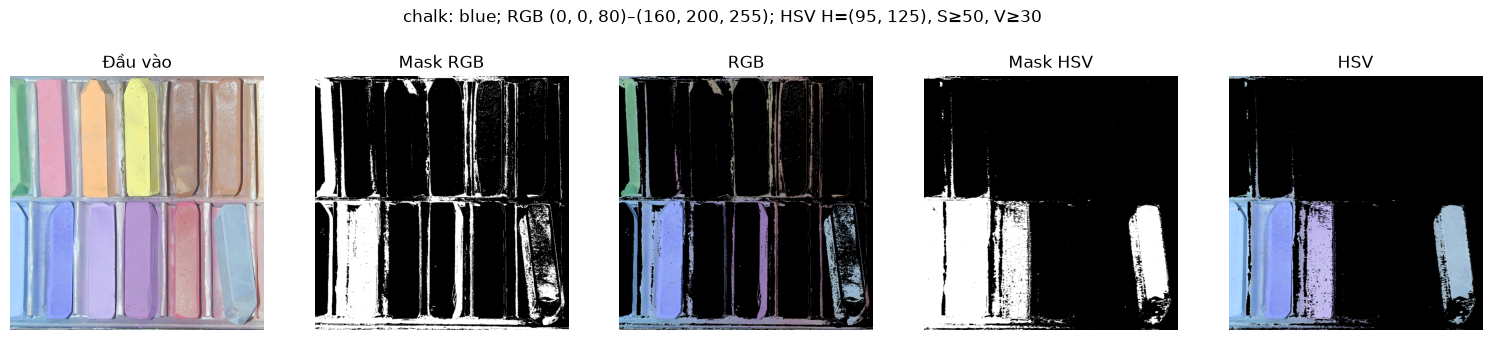

In [3]:
config = {
    "strawberries": {
        "red": ((150, 0, 0), (255, 70, 70), (170, 10), True, 90),
        "green": ((0, 35, 0), (135, 255, 135), (32, 80), False, 64),
    },
    "chalk": {
        "yellow": ((120, 100, 0), (255, 255, 170), (20, 35), False, 50),
        "blue": ((0, 0, 80), (160, 200, 255), (95, 125), False, 50),
    },
}
for name, groups in config.items():
    rgb = images[name]
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    for label, (lower, upper, hrange, wrap, smin) in groups.items():
        mrgb = segment_color_rgb(rgb, lower, upper)
        mhsv = segment_color_hsv(hsv, hrange, (smin, 255), (30, 255), wrap)
        fig, axes = plt.subplots(1, 5, figsize=(19, 4))
        panels = [rgb, mrgb, cv2.bitwise_and(rgb, rgb, mask=mrgb), mhsv, cv2.bitwise_and(rgb, rgb, mask=mhsv)]
        for ax, panel, title in zip(axes, panels, ["Đầu vào", "Mask RGB", "RGB", "Mask HSV", "HSV"]):
            ax.imshow(panel, cmap="gray" if panel.ndim == 2 else None, vmin=0, vmax=255)
            ax.set_title(title)
            ax.axis("off")
        fig.suptitle(f"{name}: {label}; RGB {lower}–{upper}; HSV H={hrange}, S≥{smin}, V≥30")
        save(fig, "1.2_segmentation_rgb_vs_hsv", f"1.2_{name}_input_vs_output_{label}_group.png")


## 3. Khảo sát ba bộ ngưỡng

Tỷ lệ foreground chỉ cho biết diện tích được chọn. Cần đối chiếu trực quan với ảnh gốc để nhận xét vùng bỏ sót hoặc chọn nhầm.


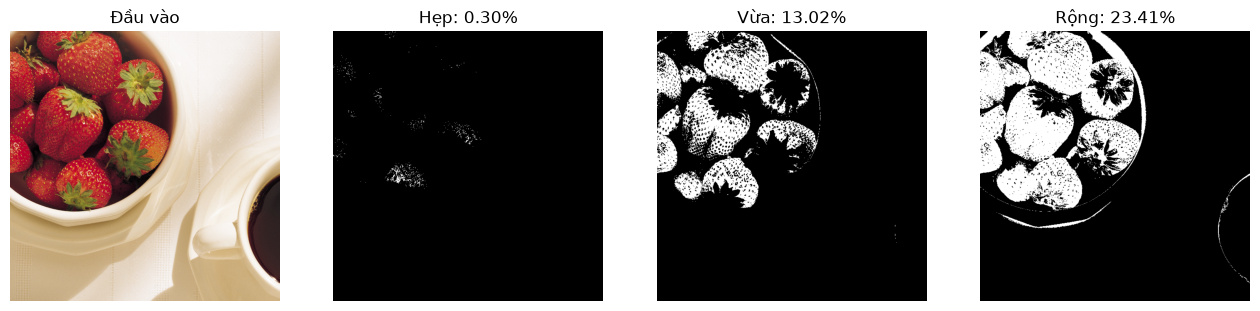

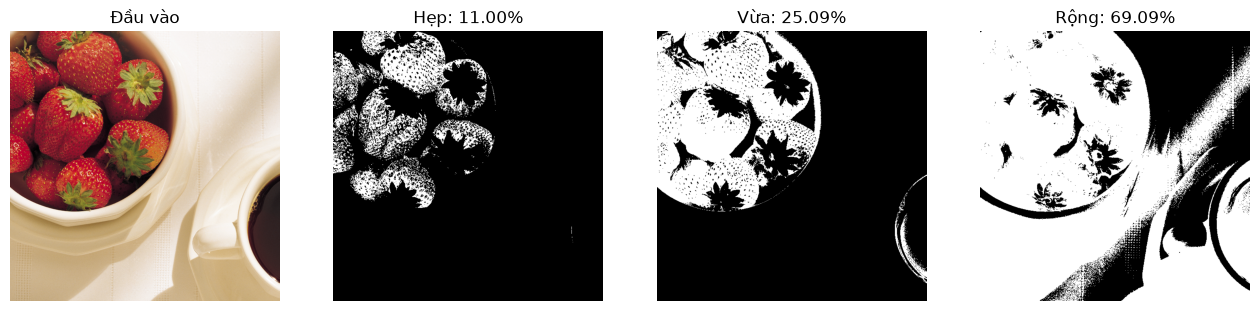

{'Không gian': 'RGB', 'Bộ ngưỡng': 'Hẹp', 'Foreground (%)': np.float64(0.29984939894849805)}
{'Không gian': 'RGB', 'Bộ ngưỡng': 'Vừa', 'Foreground (%)': np.float64(13.019776533290047)}
{'Không gian': 'RGB', 'Bộ ngưỡng': 'Rộng', 'Foreground (%)': np.float64(23.408092777462148)}
{'Không gian': 'HSV', 'Bộ ngưỡng': 'Hẹp', 'Foreground (%)': np.float64(11.000189378567757)}
{'Không gian': 'HSV', 'Bộ ngưỡng': 'Vừa', 'Foreground (%)': np.float64(25.09153297441586)}
{'Không gian': 'HSV', 'Bộ ngưỡng': 'Rộng', 'Foreground (%)': np.float64(69.08530151773395)}


In [4]:
survey = [
    ("Hẹp", (190, 0, 0), (255, 45, 45), (175, 6), 160, 120),
    ("Vừa", (140, 0, 0), (255, 85, 85), (168, 12), 90, 60),
    ("Rộng", (100, 0, 0), (255, 130, 130), (155, 25), 40, 30),
]
rows = []
rgb = images["strawberries"]
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
for method in ("RGB", "HSV"):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(rgb)
    axes[0].set_title("Đầu vào")
    axes[0].axis("off")
    for ax, (label, low, high, hrange, smin, vmin) in zip(axes[1:], survey):
        mask = (segment_color_rgb(rgb, low, high) if method == "RGB"
                else segment_color_hsv(hsv, hrange, (smin, 255), (vmin, 255), True))
        ratio = 100 * np.count_nonzero(mask) / mask.size
        rows.append({"Không gian": method, "Bộ ngưỡng": label, "Foreground (%)": ratio})
        ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{label}: {ratio:.2f}%")
        ax.axis("off")
    save(fig, "1.3_threshold_survey", f"1.3_strawberries_input_vs_output_3_thresholds_{method.lower()}.png")
for row in rows:
    print(row)
with (OUT / "1.3_threshold_survey" / "foreground_ratio.csv").open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(file, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)


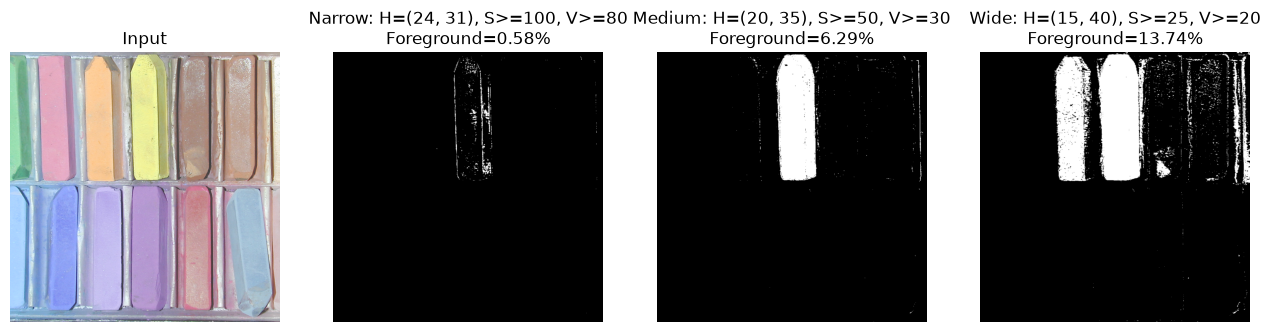

In [5]:
rgb = images['chalk']
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(rgb)
axes[0].set_title('Input')
axes[0].axis('off')
for ax, (label, hrange, smin, vmin) in zip(axes[1:], [('Narrow', (24, 31), 100, 80), ('Medium', (20, 35), 50, 30), ('Wide', (15, 40), 25, 20)]):
    mask = segment_color_hsv(hsv, hrange, (smin, 255), (vmin, 255))
    ax.imshow(mask, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{label}: H={hrange}, S>={smin}, V>={vmin}\nForeground={100*np.count_nonzero(mask)/mask.size:.2f}%')
    ax.axis('off')
save(fig, '1.3_threshold_survey', '1.3_chalk_input_vs_output_3_thresholds_hsv.png')

## Ghi nhận cho báo cáo

Với ảnh dâu, tỷ lệ foreground tăng từ 0,30% lên 23,41% trong RGB và từ 11,00% lên 69,09% trong HSV khi chuyển từ ngưỡng hẹp sang rộng. Mask HSV rộng chọn thêm nhiều vùng ngoài đối tượng; tỷ lệ foreground không đo độ chính xác.

Với ảnh phấn, ngưỡng vàng hẹp chỉ chọn 0,58% pixel và bỏ sót phần lớn viên phấn. Ngưỡng vừa chọn 6,29% và phủ phần lớn viên vàng; ngưỡng rộng chọn 13,74%, gồm cả vùng phấn cam và nền. Nhận xét này dựa trên hình thực nghiệm, chưa có mask chuẩn để tính độ chính xác.

Ghi tên ảnh, thông số và bổ sung ảnh chụp màn hình minh chứng cá nhân khi đóng gói báo cáo.
